**CLEANING:**

In [125]:
import pandas as pd

payments = pd.read_csv("olist_order_payments_dataset.csv")
print(payments.shape)
print(payments.isna().sum())
payments.head()

(103886, 5)
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [126]:
for col in ["order_id", "payment_type"]:
    payments[col] = (
        payments[col]
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", "_", regex=True)
    )

In [127]:
payments[payments["payment_type"] == "not_defined"]
#payments[(payments["payment_value"] == 0) & (payments["payment_type"] != "not_defined")]
#payments[payments["payment_installments"] == 0]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0


In [128]:

# turns not_defined payment type with a value to credit_card type
mask = (payments["payment_type"] == "not_defined") & (payments["payment_value"] != 0)
payments.loc[mask, "payment_type"] = "credit_card"



In [129]:
#  delete zero-value payments, renumber payment_sequential within each order
payments = payments.sort_values(["order_id", "payment_sequential"]).reset_index(drop=True)
is_zero = payments["payment_value"] == 0
deleted_before = is_zero.groupby(payments["order_id"]).cumsum() - is_zero.astype(int)
payments["payment_sequential"] = payments["payment_sequential"] - deleted_before
payments = payments[~is_zero].reset_index(drop=True)

In [130]:
#installments of 0 -> 1
payments.loc[payments["payment_installments"] == 0, "payment_installments"] = 1


In [131]:
print(payments.shape)
print(payments["payment_type"].value_counts())

(103877, 5)
payment_type
credit_card    76795
boleto         19784
voucher         5769
debit_card      1529
Name: count, dtype: int64


In [132]:
payments = payments.sort_values(["order_id", "payment_sequential"]).reset_index(drop=True)

# not_defined with a non-zero value -> credit_card (0 rows in this dataset)
mask = (payments["payment_type"] == "not_defined") & (payments["payment_value"] != 0)
payments.loc[mask, "payment_type"] = "credit_card"

# delete zero-value payments, renumber payment_sequential inside each order
is_zero = payments["payment_value"] == 0
deleted_before = is_zero.groupby(payments["order_id"]).cumsum() - is_zero.astype(int)
payments["payment_sequential"] = payments["payment_sequential"] - deleted_before
payments = payments[~is_zero].reset_index(drop=True)

# installments of 0 -> 1
payments.loc[payments["payment_installments"] == 0, "payment_installments"] = 1

# stop with an error if anything is off
assert payments.shape == (103877, 5), payments.shape
assert "not_defined" not in payments["payment_type"].unique()
assert (payments["payment_installments"] >= 1).all()
assert (payments["payment_value"] > 0).all()

payments.to_csv("olist_order_payments_clean.csv", index=False)

**VISUALISATION :**


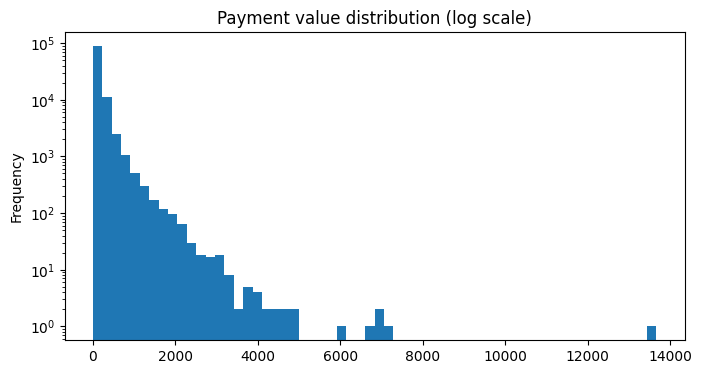

In [133]:
import matplotlib.pyplot as plt
payments["payment_value"].plot(kind="hist", bins=60, log=True, figsize=(8,4))
plt.title("Payment value distribution (log scale)"); plt.show()

# most products sold are between [0;3000]

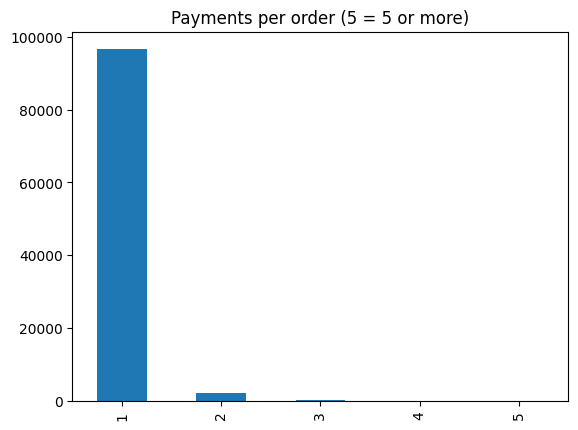

In [134]:
payments.groupby("order_id").size().clip(upper=5).value_counts().sort_index().plot(kind="bar")
plt.title("Payments per order (5 = 5 or more)"); plt.show()

#most orders where payed once

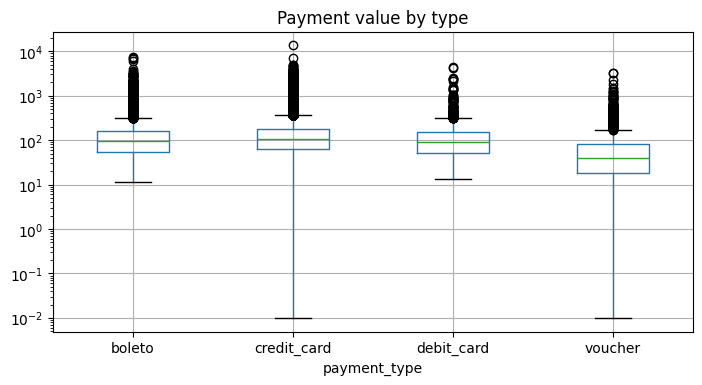

In [135]:
payments.boxplot(column="payment_value", by="payment_type", figsize=(8,4))
plt.yscale("log"); plt.suptitle(""); plt.title("Payment value by type"); plt.show()


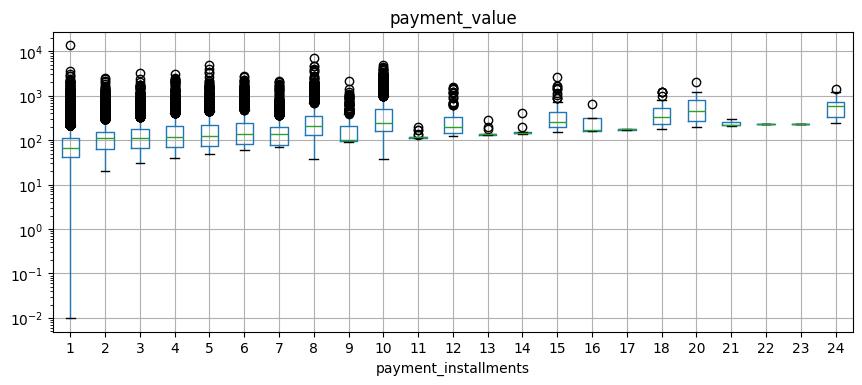

In [136]:
cc = payments[payments["payment_type"] == "credit_card"]
cc.boxplot(column="payment_value", by="payment_installments", figsize=(10,4))
plt.yscale("log"); plt.suptitle(""); plt.show()

In [137]:
print((payments["payment_value"] <= 0).sum())           # expect 0

0


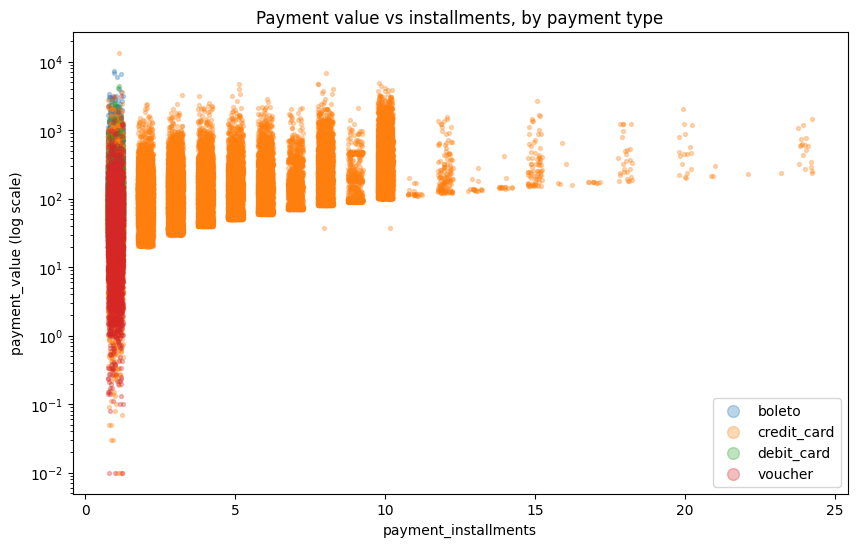

In [138]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
jitter = rng.uniform(-0.25, 0.25, len(payments))

fig, ax = plt.subplots(figsize=(10, 6))
for ptype, g in payments.groupby("payment_type"):
    ax.scatter(g["payment_installments"] + jitter[g.index],
               g["payment_value"],
               s=8, alpha=0.3, label=ptype)

ax.set_yscale("log")
ax.set_xlabel("payment_installments")
ax.set_ylabel("payment_value (log scale)")
ax.set_title("Payment value vs installments, by payment type")
ax.legend(markerscale=3)
plt.show()

**TRANSFORMATION:(onehotencoder and aggrigation)**

In [139]:
dummies = pd.get_dummies(payments["payment_type"], prefix="n", dtype=int)
count_cols = list(dummies.columns)          # e.g. n_credit_card, n_boleto, ...

# drop first so the cell can be rerun without duplicating columns
payments = pd.concat([payments.drop(columns=count_cols, errors="ignore"), dummies], axis=1)

assert (payments[count_cols].sum(axis=1) == 1).all()   # exactly one type per row
payments.head(10)

,order_id,payment_sequential,payment_type,payment_installments,payment_value,n_boleto,n_credit_card,n_debit_card,n_voucher
0,00010242fe8c5a6d1ba2dd792cb16214,1,credit_card,2,72.19,0,1,0,0
1,00018f77f2f0320c557190d7a144bdd3,1,credit_card,3,259.83,0,1,0,0
2,000229ec398224ef6ca0657da4fc703e,1,credit_card,5,216.87,0,1,0,0
3,00024acbcdf0a6daa1e931b038114c75,1,credit_card,2,25.78,0,1,0,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,credit_card,3,218.04,0,1,0,0
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,boleto,1,34.59,1,0,0,0
6,00054e8431b9d7675808bcb819fb4a32,1,credit_card,1,31.75,0,1,0,0
7,000576fe39319847cbb9d288c5617fa6,1,credit_card,10,880.75,0,1,0,0
8,0005a1a1728c9d785b8e2b08b904576c,1,credit_card,3,157.60,0,1,0,0
9,0005f50442cb953dcd1d21e1fb923495,1,credit_card,1,65.39,0,1,0,0


In [140]:
# Counts: sum of the one-hot columns per order
type_counts = payments.groupby("order_id")[count_cols].sum()

# Total paid per type
type_values = payments.pivot_table(index="order_id", columns="payment_type",
                                   values="payment_value", aggfunc="sum", fill_value=0)
type_values.columns = [f"value_{c}" for c in type_values.columns]

type_features = type_counts.join(type_values)

assert type_features.index.is_unique
assert type_features.index.nunique() == payments["order_id"].nunique()
type_features.head(10)

,n_boleto,n_credit_card,n_debit_card,n_voucher,value_boleto,value_credit_card,value_debit_card,value_voucher
order_id,,,,,,,,
00010242fe8c5a6d1ba2dd792cb16214,0,1,0,0,0.00,72.19,0.0,0.0
00018f77f2f0320c557190d7a144bdd3,0,1,0,0,0.00,259.83,0.0,0.0
000229ec398224ef6ca0657da4fc703e,0,1,0,0,0.00,216.87,0.0,0.0
00024acbcdf0a6daa1e931b038114c75,0,1,0,0,0.00,25.78,0.0,0.0
00042b26cf59d7ce69dfabb4e55b4fd9,0,1,0,0,0.00,218.04,0.0,0.0
00048cc3ae777c65dbb7d2a0634bc1ea,1,0,0,0,34.59,0.00,0.0,0.0
00054e8431b9d7675808bcb819fb4a32,0,1,0,0,0.00,31.75,0.0,0.0
000576fe39319847cbb9d288c5617fa6,0,1,0,0,0.00,880.75,0.0,0.0
0005a1a1728c9d785b8e2b08b904576c,0,1,0,0,0.00,157.60,0.0,0.0


In [141]:
#aggregation
order_agg = payments.groupby("order_id").agg(
    n_payments=("payment_sequential", "size"),
    total_paid=("payment_value", "sum"),
    max_payment=("payment_value", "max"),
    min_payment=("payment_value", "min"),
    max_installments=("payment_installments", "max"),
    n_payment_types=("payment_type", "nunique"),
)

assert order_agg.index.is_unique
assert abs(order_agg["total_paid"].sum() - payments["payment_value"].sum()) < 0.01

In [142]:
#concat
order_payments = order_agg.join(type_features).reset_index()
value_cols = [c for c in type_features.columns if c.startswith("value_")]

assert order_payments["order_id"].is_unique
assert len(order_payments) == payments["order_id"].nunique()
assert (order_payments[count_cols].sum(axis=1) == order_payments["n_payments"]).all()
assert abs(order_payments[value_cols].sum(axis=1) - order_payments["total_paid"]).max() < 0.01

In [143]:
order_payments[order_payments["n_payments"] > 2]

,order_id,n_payments,total_paid,max_payment,min_payment,max_installments,n_payment_types,n_boleto,n_credit_card,n_debit_card,n_voucher,value_boleto,value_credit_card,value_debit_card,value_voucher
215,009ac365164f8e06f59d18a08045f6c4,6,32.00,8.75,0.88,1,2,0,1,0,5,0.0,0.88,0.0,31.12
273,00bd50cdd31bd22e9081e6e2d5b3577b,3,85.80,40.46,4.88,1,2,0,1,0,2,0.0,4.88,0.0,80.92
281,00c405bd71187154a7846862f585a9d4,7,46.69,20.00,0.10,1,2,0,1,0,6,0.0,6.03,0.0,40.66
294,00c95282163553a982f38481f9488481,4,124.90,64.90,20.00,1,2,0,1,0,3,0.0,64.90,0.0,60.00
1401,039f61edec89c6f0edf8dd1a0bdea1fe,3,316.22,166.22,50.00,10,2,0,1,0,2,0.0,166.22,0.0,150.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98850,fe678293ea3bb6607a15b2e320e91722,6,101.78,20.00,1.78,1,1,0,0,0,6,0.0,0.00,0.0,101.78
99017,fedcd9f7ccdc8cba3a18defedd1a5547,19,205.74,31.43,1.67,1,2,0,1,0,18,0.0,1.67,0.0,204.07
99070,fefbe15ebcd87ab3fb8577e635a8b31c,6,28.19,8.29,2.84,1,2,0,1,0,5,0.0,8.29,0.0,19.90
99120,ff1f8f328e5a59ac754240b6dd31bcb4,4,258.06,142.58,11.17,1,2,0,1,0,3,0.0,11.17,0.0,246.89


In [144]:
from google.colab import files

order_payments.to_csv("order_payments_clean.csv", index=False)
files.download("order_payments_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>